## AUTOML : **H2O AutoML**


### Instalación (Colab)

Si estás en Colab, ejecuta esta celda una vez. En local quizá ya lo tengas instalado.

In [1]:
!pip -q install -U h2o

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 266.4/266.4 MB 4.8 MB/s eta 0:00:00


### Carga de datos

In [2]:
import os
import pandas as pd

CANDIDATES = [
    "./bank-full.csv",
    "/content/bank-full.csv",
]

csv_path = next((p for p in CANDIDATES if os.path.exists(p)), None)

if csv_path is None:
    try:
        from google.colab import files
        print("No encuentro bank-full.csv. Sube el fichero ahora (bank-full.csv)...")
        uploaded = files.upload()
        if "bank-full.csv" in uploaded:
            csv_path = "bank-full.csv"
    except Exception:
        pass

if csv_path is None:
    raise FileNotFoundError(
        "No se encontró bank-full.csv. Colócalo en la ruta ../bank-full.csv o ./bank-full.csv "
        "o súbelo en Colab con files.upload()."
    )

df_bank = pd.read_csv(csv_path, sep=";")
df_bank.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df_bank.y.value_counts()

,count
y,
no,39922
yes,5289


In [4]:
df_bank.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [5]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df_bank,
    test_size=0.2,
    random_state=123,
    stratify=df_bank["y"]
)

train_df.shape, test_df.shape


((36168, 17), (9043, 17))

### Entrenar H2O AutoML

In [6]:
import h2o
from h2o.automl import H2OAutoML

h2o.init()

# Convertimos a H2OFrame
train_h2o = h2o.H2OFrame(train_df)
test_h2o = h2o.H2OFrame(test_df)

target = "y"
features = [c for c in train_h2o.columns if c != target]

# Para clasificación, la variable objetivo debe ser factor
train_h2o[target] = train_h2o[target].asfactor()
test_h2o[target] = test_h2o[target].asfactor()

aml = H2OAutoML(
    max_models=2,          # ajusta según tiempo de clase
    seed=123,
    sort_metric="AUC",
    exclude_algos=None      # puedes excluir si quieres simplificar
)
aml.train(x=features, y=target, training_frame=train_h2o)

aml.leaderboard.head()


Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "17.0.17" 2025-10-21; OpenJDK Runtime Environment (build 17.0.17+10-Ubuntu-122.04); OpenJDK 64-Bit Server VM (build 17.0.17+10-Ubuntu-122.04, mixed mode, sharing)
  Starting server from /usr/local/lib/python3.12/dist-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmpe88m1dpv
  JVM stdout: /tmp/tmpe88m1dpv/h2o_unknownUser_started_from_python.out
  JVM stderr: /tmp/tmpe88m1dpv/h2o_unknownUser_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,04 secs
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.10
H2O_cluster_version_age:,1 day
H2O_cluster_name:,H2O_from_python_unknownUser_ozznhi
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.168 Gb
H2O_cluster_total_cores:,2
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"


Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%


model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse
StackedEnsemble_BestOfFamily_1_AutoML_1_20260314_100020,0.930715,0.205287,0.60263,0.168827,0.253721,0.0643745
XGBoost_1_AutoML_1_20260314_100020,0.929179,0.208675,0.59536,0.178563,0.256844,0.065969
GLM_1_AutoML_1_20260314_100020,0.908776,0.238258,0.553594,0.195021,0.266187,0.0708557


In [7]:
train_h2o.summary()

/tmp/ipykernel_306/1575823005.py:1: H2ODeprecationWarning: ``summary()`` is deprecated, please use ``show_summary()`` or ``get_summary()`` instead
  train_h2o.summary()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
type,int,enum,enum,enum,enum,int,enum,enum,enum,int,enum,int,int,int,int,enum,enum
mins,18.0,,,,,-6847.0,,,,1.0,,0.0,1.0,-1.0,0.0,,
mean,40.984544348595364,,,,,1371.7049325370424,,,,15.829130723291387,,257.70258239327393,2.774524441495219,40.479346383543685,0.5844669320946714,,
maxs,95.0,,,,,102127.0,,,,31.0,,3881.0,58.0,871.0,275.0,,
sigma,10.654675769300122,,,,,3045.9751394221157,,,,8.320045673200662,,256.0400478203298,3.1005323270619876,100.38766158935638,2.409003957443737,,
zeros,0,,,,,2801,,,,0,,3,0,0,29523,,
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,37.0,technician,married,secondary,no,101.0,no,no,cellular,17.0,jul,130.0,1.0,-1.0,0.0,unknown,no
1,46.0,management,married,secondary,no,1098.0,no,no,cellular,8.0,may,99.0,3.0,343.0,3.0,other,no
2,50.0,management,married,primary,no,15035.0,yes,no,cellular,12.0,may,158.0,1.0,-1.0,0.0,unknown,no


In [8]:
train_h2o.nacnt()

[0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0]

In [9]:
train_h2o["job"].levels()

[['admin.',
  'blue-collar',
  'entrepreneur',
  'housemaid',
  'management',
  'retired',
  'self-employed',
  'services',
  'student',
  'technician',
  'unemployed',
  'unknown']]

In [10]:
train_h2o.types

{'age': 'int',
 'job': 'enum',
 'marital': 'enum',
 'education': 'enum',
 'default': 'enum',
 'balance': 'int',
 'housing': 'enum',
 'loan': 'enum',
 'contact': 'enum',
 'day': 'int',
 'month': 'enum',
 'duration': 'int',
 'campaign': 'int',
 'pdays': 'int',
 'previous': 'int',
 'poutcome': 'enum',
 'y': 'enum'}

In [11]:
from google.colab import output
import h2o

# Obtener el puerto real del servidor H2O
base_url = h2o.connection().base_url
port = int(base_url.split(":")[-1])

print(f"H2O Flow corriendo en: {base_url}")

# Abrir Flow en una ventana de Colab
output.serve_kernel_port_as_window(
    port=port,
    path="/flow/index.html"
)


H2O Flow corriendo en: http://127.0.0.1:54321
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

### Mejor modelo (leader) y evaluación

In [12]:
leader = aml.leader
leader


Model Details
=============
H2OStackedEnsembleEstimator : Stacked Ensemble
Model Key: StackedEnsemble_BestOfFamily_1_AutoML_1_20260314_100020


Model Summary for Stacked Ensemble: 
key                                   value
------------------------------------  ----------------
Stacking strategy                     cross_validation
Number of base models (used / total)  2/2
# XGBoost base models (used / total)  1/1
# GLM base models (used / total)      1/1
Metalearner algorithm                 GLM
Metalearner fold assignment scheme    Random
Metalearner nfolds                    5
Metalearner fold_column
Custom metalearner hyperparameters    None

ModelMetricsBinomialGLM: stackedensemble
** Reported on train data. **

MSE: 0.04715335228099746
RMSE: 0.21714822652049787
LogLoss: 0.15862233568675013
AUC: 0.9645612837986337
AUCPR: 0.7996230262432134
Gini: 0.9291225675972674
Null degrees of freedom: 10057
Residual degrees of freedom: 10055
Null deviance: 7317.422795075013
Residual deviance: 3190.8469046746663
AIC: 3196.8469046746663

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.32238560347402384
       no    yes    Error    Rate
-----  ----  -----  -------  ---------------
no     8455  412    0.0465   (412.0/8867.0)
yes    240   951    0.2015   (240.0/1191.0)
Total  8695  1363   0.0648   (652.0/10058.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.322386     0.744714  192
max f2                       0.182178     0.804091  245
max f0point5                 0.481439     0.743089  136
max accuracy                 0.4113       0.937363  161
max precision                0.96348      1         0
max recall                   0.00579249   1         386
max specificity              0.96348      1         0
max absolute_mcc             0.322386     0.709894  192
max min_per_class_accuracy   0.182178     0.903462  245
max mean_per_class_accuracy  0.142277     0.907081  264
max tns                      0.96348      8867      0
max fns                      0.96348      1188      0
max fps                      0.00102234   8867      399
max tps                      0.00579249   1191      386
max tnr                      0.96348      1         0
max fnr                      0.96348      0.997481  0
max fpr                      0.00102234   1         399
max tpr                      0.00579249   1         386

Gains/Lift Table: Avg response rate: 11.84 %, avg score: 11.70 %
group    cumulative_data_fraction    lower_threshold    lift       cumulative_lift    response_rate    score       cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  ---------  -----------------  ---------------  ----------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.0100418                   0.849052           8.27778    8.27778            0.980198         0.892766    0.980198                    0.892766            0.0831234       0.0831234                  727.778   727.778            0.0828979
2        0.0200835                   0.784776           7.52525    7.90151            0.891089         0.812799    0.935644                    0.852783            0.0755668       0.15869                    652.525   690.151            0.157224
3        0.0300259                   0.732616           7.7694     7.85777            0.92             0.76086     0.930464                    0.822345            0.077246        0.235936                   676.94    685.777            0.233568
4        0.0400676                   0.691868           7.35802    7.73252            0.871287         0.709985    0.915633                    0.794185            0.0738875       0.30982

In [13]:
perf = leader.model_performance(test_data=test_h2o)
perf


ModelMetricsBinomialGLM: stackedensemble
** Reported on test data. **

MSE: 0.06415279979219006
RMSE: 0.2532840298798763
LogLoss: 0.20684692286921308
AUC: 0.9279614541916377
AUCPR: 0.607143548788857
Gini: 0.8559229083832753
Null degrees of freedom: 9042
Residual degrees of freedom: 9040
Null deviance: 6527.198493906685
Residual deviance: 3741.0334470125877
AIC: 3747.0334470125877

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.2523831454752392
       no    yes    Error    Rate
-----  ----  -----  -------  --------------
no     7333  652    0.0817   (652.0/7985.0)
yes    287   771    0.2713   (287.0/1058.0)
Total  7620  1423   0.1038   (939.0/9043.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.252383     0.621524  215
max f2                       0.128934     0.724258  271
max f0point5                 0.532268     0.602523  117
max accuracy                 0.535077     0.908548  116
max precision                0.967161     1         0
max recall                   0.00217834   1         397
max specificity              0.967161     1         0
max absolute_mcc             0.206072     0.571612  235
max min_per_class_accuracy   0.133137     0.857278  269
max mean_per_class_accuracy  0.127024     0.859157  272
max tns                      0.967161     7985      0
max fns                      0.967161     1055      0
max fps                      0.0013716    7985      399
max tps                      0.00217834   1058      397
max tnr                      0.967161     1         0
max fnr                      0.967161     0.997164  0
max fpr                      0.0013716    1         399
max tpr                      0.00217834   1         397

Gains/Lift Table: Avg response rate: 11.70 %, avg score: 11.54 %
group    cumulative_data_fraction    lower_threshold    lift        cumulative_lift    response_rate    score       cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  ----------  -----------------  ---------------  ----------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.010063                    0.846694           6.66874     6.66874            0.78022          0.893164    0.78022                     0.893164            0.0671078       0.0671078                  566.874   566.874            0.0646031
2        0.0200155                   0.783126           6.36296     6.51669            0.744444         0.815497    0.762431                    0.854545            0.063327        0.130435                   536.296   551.669            0.12505
3        0.0300785                   0.727619           6.19911     6.41044            0.725275         0.75758     0.75                        0.822104            0.0623819       0.192817                   519.911   541.044            0.184301
4        0.040031                    0.675454           5.98308     6.30419            0.7              0.700094    0.737569                    0.79177             0.0595463       0.252363                   498.308   530.419            0.240466
5        0.050094                    0.627445           5.16593     6.07554            0.604396         0.65086     0.710817                    0.763464            0.0519849       0.304348                   416.593   507.554            0.287942
6        0.100077                    0.432338           4.44382     5.26058            0.519912         0.528007    0.61547                     0.645866            0.222117        0.526465                   344.382   426.058            0.482883
7        0.150061                    0.271153           3.46051     4.661              0.404867         0.34627

In [14]:
# Métricas típicas
print("AUC:", perf.auc())
print("LogLoss:", perf.logloss())


AUC: 0.9279614541916377
LogLoss: 0.20684692286921308


In [15]:
# Matriz de confusión (umbral por defecto)
perf.confusion_matrix()


,no,yes,Error,Rate
no,7333.0,652.0,0.0817,(652.0/7985.0)
yes,287.0,771.0,0.2713,(287.0/1058.0)
Total,7620.0,1423.0,0.1038,(939.0/9043.0)


### Predicciones

In [16]:
preds = leader.predict(test_h2o)
preds.head()


stackedensemble prediction progress: |███████████████████████████████████████████| (done) 100%


predict,no,yes
no,0.996008,0.00399216
no,0.971703,0.0282971
no,0.993366,0.00663419
no,0.998746,0.00125368
yes,0.596669,0.403331
no,0.797604,0.202396
no,0.891834,0.108166
no,0.981755,0.0182452
no,0.993789,0.0062115
no,0.948197,0.0518033


In [17]:
# Pasar a pandas si lo necesitas
preds_df = preds.as_data_frame()
preds_df.head()


/usr/local/lib/python3.12/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,predict,no,yes
0,no,0.996008,0.003992
1,no,0.971703,0.028297
2,no,0.993366,0.006634
3,no,0.998746,0.001254
4,yes,0.596669,0.403331


## si solo quiero un modelo concreto...

In [18]:
from h2o.estimators.xgboost import H2OXGBoostEstimator

xgb = H2OXGBoostEstimator(
    ntrees=300,
    max_depth=6,
    learn_rate=0.05,
    seed=123
)

xgb.train(
    x=features,
    y=target,
    training_frame=train_h2o
)


xgboost Model Build progress: |██████████████████████████████████████████████████| (done) 100%


Model Details
=============
H2OXGBoostEstimator : XGBoost
Model Key: XGBoost_model_python_1773482403493_472


Model Summary: 
    number_of_trees
--  -----------------
    300

ModelMetricsBinomial: xgboost
** Reported on train data. **

MSE: 0.04478282684234256
RMSE: 0.21161953322494254
LogLoss: 0.14956038194392543
Mean Per-Class Error: 0.13392265040943768
AUC: 0.9677677180967993
AUCPR: 0.8230896271070679
Gini: 0.9355354361935986

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.3584903964289912
       no     yes    Error    Rate
-----  -----  -----  -------  ----------------
no     30516  1421   0.0445   (1421.0/31937.0)
yes    945    3286   0.2234   (945.0/4231.0)
Total  31461  4707   0.0654   (2366.0/36168.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.35849      0.735288  192
max f2                       0.189813     0.799071  257
max f0point5                 0.554807     0.775948  122
max accuracy                 0.453056     0.940002  157
max precision                0.976568     1         0
max recall                   0.00670092   1         382
max specificity              0.976568     1         0
max absolute_mcc             0.35849      0.69938   192
max min_per_class_accuracy   0.189813     0.901588  257
max mean_per_class_accuracy  0.136985     0.905524  281
max tns                      0.976568     31937     0
max fns                      0.976568     4226      0
max fps                      0.000329699  31937     399
max tps                      0.00670092   4231      382
max tnr                      0.976568     1         0
max fnr                      0.976568     0.998818  0
max fpr                      0.000329699  1         399
max tpr                      0.00670092   1         382

Gains/Lift Table: Avg response rate: 11.70 %, avg score: 11.70 %
group    cumulative_data_fraction    lower_threshold    lift        cumulative_lift    response_rate    score        cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  ----------  -----------------  ---------------  -----------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.0100088                   0.883708           8.40665     8.40665            0.983425         0.921092     0.983425                    0.921092            0.0841409       0.0841409                  740.665   740.665            0.083953
2        0.0200177                   0.819077           8.28858     8.34761            0.969613         0.850644     0.976519                    0.885868            0.0829591       0.1671                     728.858   734.761            0.166568
3        0.0300265                   0.754361           7.91075     8.20199            0.925414         0.785909     0.959484                    0.852548            0.0791775       0.246277                   691.075   720.199            0.2449
4        0.0400077                   0.70096            7.93266     8.1348             0.927978         0.727065     0.951624                    0.821243            0.0791775       0.325455                   693.266   713.48             0.323263
5        0.0500166                   0.653328           7.17871     7.94348            0.839779         0.677112     0.929243                    0.792401            0.0718506       0.397306                   617.871   694.348            0.393298
6        0.100006                    0.459174           5.442       6.69308            0.636615         0.553396     0.782969                    0.672931            0.27204         0.669345                   444.2     569.308            0.644766
7        0.150022                    0.295

### Importancia de variables (si el modelo la soporta)

In [19]:
xgb.varimp(use_pandas=True)

,variable,relative_importance,scaled_importance,percentage
0,duration,59448.593750,1.000000,0.407777
1,poutcome.success,16384.716797,0.275612,0.112388
2,day,8603.600586,0.144723,0.059015
3,age,7444.037109,0.125218,0.051061
4,balance,6320.619141,0.106321,0.043355
5,contact.unknown,6226.484375,0.104737,0.042709
6,pdays,5816.150391,0.097835,0.039895
7,housing.no,4476.444824,0.075299,0.030705
8,month.mar,3010.412109,0.050639,0.020649
9,month.jun,2581.205322,0.043419,0.017705


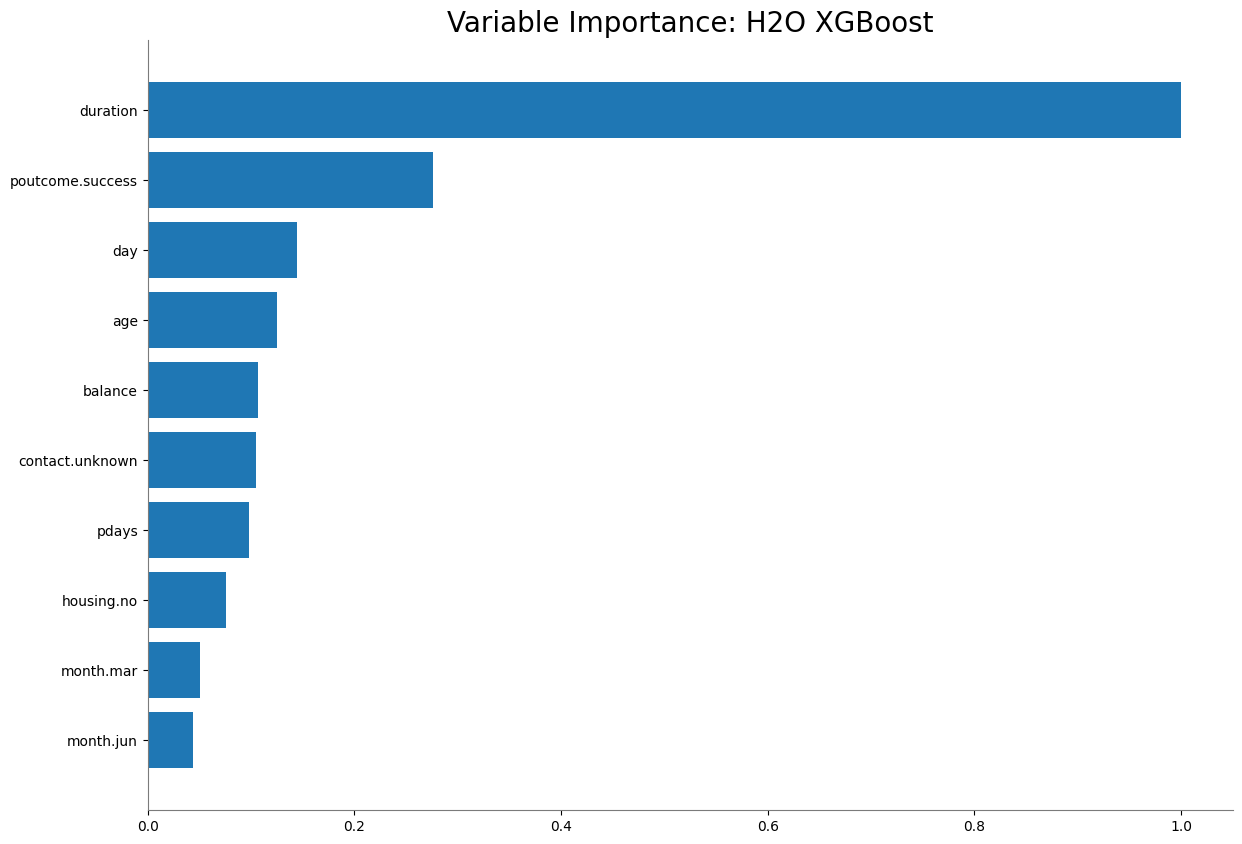

<Figure size 640x480 with 0 Axes>

In [20]:
xgb.varimp_plot()

In [21]:
contrib = xgb.predict_contributions(test_h2o)
contrib.head()


contributions progress: |████████████████████████████████████████████████████████| (done) 100%


job.admin.,job.blue-collar,job.entrepreneur,job.housemaid,job.management,job.retired,job.self-employed,job.services,job.student,job.technician,job.unemployed,job.unknown,job.missing(NA),month.apr,month.aug,month.dec,month.feb,month.jan,month.jul,month.jun,month.mar,month.may,month.nov,month.oct,month.sep,month.missing(NA),education.primary,education.secondary,education.tertiary,education.unknown,education.missing(NA),poutcome.failure,poutcome.other,poutcome.success,poutcome.unknown,poutcome.missing(NA),marital.divorced,marital.married,marital.single,marital.missing(NA),contact.cellular,contact.telephone,contact.unknown,contact.missing(NA),default.no,default.yes,default.missing(NA),housing.no,housing.yes,housing.missing(NA),loan.no,loan.yes,loan.missing(NA),age,balance,day,duration,campaign,pdays,previous,BiasTerm
-0.0393325,0.0143936,-0.000281616,0.0076288,-0.00165343,0.000899235,0.00114125,0.0220167,-0.00658083,0.00111012,-0.0112965,0.000419459,0,-0.0405452,0.0178407,-0.00753578,-0.00994687,-0.00171559,0.0653872,-0.0398855,-0.0740047,-0.804814,-0.0453617,-0.0364078,-0.0340414,0,0.0185701,-0.00183908,-0.0554394,-0.0065821,0,0.00088,-0.00858587,-0.0714454,-0.00680178,0,0.0271441,0.118619,-0.00372142,0,0.0979606,0.00233424,0.107447,0,-0.000362278,0,0,-0.170763,0,0,0.0213354,0,0,-0.114348,-0.659264,-0.218962,-2.33839,0.14235,-0.0187837,-0.0115936,-2.27138
0.101613,0.00523347,0.00228315,0.00920149,-0.0034422,0.000616183,0.0022068,0.00541184,-0.00195562,0.000894928,-0.000869391,0.000891188,0,-0.0130376,0.0115474,-0.0131683,-0.00774893,-0.011782,0.0510867,-0.0250474,-0.047533,-0.503258,-0.0468142,-0.0365865,-0.0345544,0,0.012284,0.00350902,0.126523,-0.00978712,0,0.00138881,-0.0175764,-0.0591682,-0.00618533,0,0.0226844,0.0801704,-0.00766053,0,-0.258975,-0.00123674,-0.970941,0,-0.00164794,0,0,-0.241568,0,0,0.0150222,0,0,-0.100792,0.0612929,-0.0831782,-0.124311,-0.0550354,-0.00711739,-0.00715973,-2.27138
-0.0194787,-0.000312743,0.000841344,0.00591534,-0.00163379,0.00320754,0.00415299,-0.0282454,-0.00320122,0.000199955,-0.00130631,0.001762,0,-0.0287925,0.039015,-0.00525492,-0.108911,0.00436434,0.0630222,0.34656,-0.0412984,0.175971,0.0302222,-0.0624692,-0.0370452,0,0.0128876,-0.00386748,-0.0349104,-0.00325544,0,0.00438926,-0.0151865,-0.0664126,-0.0241782,0,-0.00492059,-0.0811648,-0.0039816,0,-0.517167,-0.00619142,-0.65742,0,-0.000911605,0,0,-0.14572,0,0,0.0231264,0,0,-0.103031,0.06702,-0.177151,-1.83589,-0.504934,-0.0483205,-0.0302038,-2.27138
-0.0226105,-0.028822,0.000636509,0.00206902,0.000439723,0.0021699,0.00218899,0.000146784,-0.0172677,0.000492605,-0.000635213,0.000338177,0,-0.07247,0.0163753,-0.00753529,-0.0788787,0.0159473,-0.336313,-0.0264953,-0.0253322,0.0303352,-0.00403553,-0.0422085,-0.0178108,0,0.015567,-0.00204669,-0.0451284,-0.00199674,0,-0.000803332,-0.0276203,-0.0763091,-0.0139087,0,-0.00437131,-0.0615043,-0.0178106,0,-0.0416212,-0.00103295,0.0635557,0,-0.000783513,0,0,-0.0969248,0,0,-0.160046,0,0,-0.0960964,0.0230493,0.0196376,-3.9395,-0.589329,-0.0629312,-0.0276185,-2.27138
-0.0140995,-0.0186935,0.000851437,0.00740117,5.23214e-05,0.000970363,0.00330581,0.0070299,-0.00163097,-0.00211067,-0.000303285,0.00136434,0,-0.0290824,0.0043168,-0.0101752,0.198443,-0.00590447,0.0185217,-0.0375032,-0.028984,0.0668306,-0.0282884,-0.0189894,-0.0221725,0,-0.0697731,0.00494741,-0.0612923,-0.0020978,0,0.00360522,0.00222791,-0.0558125,0.00811653,0,-0.004473,-0.0464182,-0.00872225,0,-0.115317,-0.00715025,0.117276,0,-0.00251207,0,0,0.0987815,0,0,0.0166047,0,0,-0.0598762,0.275273,-0.288675,2.60707,-0.106192,-0.0131239,-0.0066306,-2.27138
-0.0104399,0.0140219,0.00331516,0.00927534,0.00812843,0.000658684,0.00102313,0.000492706,-0.00178482,0.00323874,-0.000569995,0.000550222,0,-0.0567257,-0.00131481,-0.00555167,-0.0589182,0.012383,0.056579,-0.0307351,-0.0311351,0.0178551,-0.191216,-0.0273812,-0.0287935,0,0.00750499,0.00336917,0.064856,0.000932436,0,0.00290015,-0.0100466,-0.0859048,0.000371791,0,-0.00286581,0.0678425,0.0300587,0,-0.00510038,0.00

### Guardar y cargar el modelo

In [22]:
import os

model_path = h2o.save_model(model=leader, path="/content", force=True)
print("Guardado en:", model_path)

loaded = h2o.load_model(model_path)
loaded


Guardado en: /content/StackedEnsemble_BestOfFamily_1_AutoML_1_20260314_100020


Model Details
=============
H2OStackedEnsembleEstimator : Stacked Ensemble
Model Key: StackedEnsemble_BestOfFamily_1_AutoML_1_20260314_100020


Model Summary for Stacked Ensemble: 
key                                   value
------------------------------------  ----------------
Stacking strategy                     cross_validation
Number of base models (used / total)  2/2
# XGBoost base models (used / total)  1/1
# GLM base models (used / total)      1/1
Metalearner algorithm                 GLM
Metalearner fold assignment scheme    Random
Metalearner nfolds                    5
Metalearner fold_column
Custom metalearner hyperparameters    None

ModelMetricsBinomialGLM: stackedensemble
** Reported on train data. **

MSE: 0.04715335228099746
RMSE: 0.21714822652049787
LogLoss: 0.15862233568675013
AUC: 0.9645612837986337
AUCPR: 0.7996230262432134
Gini: 0.9291225675972674
Null degrees of freedom: 10057
Residual degrees of freedom: 10055
Null deviance: 7317.422795075013
Residual deviance: 3190.8469046746663
AIC: 3196.8469046746663

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.32238560347402384
       no    yes    Error    Rate
-----  ----  -----  -------  ---------------
no     8455  412    0.0465   (412.0/8867.0)
yes    240   951    0.2015   (240.0/1191.0)
Total  8695  1363   0.0648   (652.0/10058.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.322386     0.744714  192
max f2                       0.182178     0.804091  245
max f0point5                 0.481439     0.743089  136
max accuracy                 0.4113       0.937363  161
max precision                0.96348      1         0
max recall                   0.00579249   1         386
max specificity              0.96348      1         0
max absolute_mcc             0.322386     0.709894  192
max min_per_class_accuracy   0.182178     0.903462  245
max mean_per_class_accuracy  0.142277     0.907081  264
max tns                      0.96348      8867      0
max fns                      0.96348      1188      0
max fps                      0.00102234   8867      399
max tps                      0.00579249   1191      386
max tnr                      0.96348      1         0
max fnr                      0.96348      0.997481  0
max fpr                      0.00102234   1         399
max tpr                      0.00579249   1         386

Gains/Lift Table: Avg response rate: 11.84 %, avg score: 11.70 %
group    cumulative_data_fraction    lower_threshold    lift       cumulative_lift    response_rate    score       cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  ---------  -----------------  ---------------  ----------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.0100418                   0.849052           8.27778    8.27778            0.980198         0.892766    0.980198                    0.892766            0.0831234       0.0831234                  727.778   727.778            0.0828979
2        0.0200835                   0.784776           7.52525    7.90151            0.891089         0.812799    0.935644                    0.852783            0.0755668       0.15869                    652.525   690.151            0.157224
3        0.0300259                   0.732616           7.7694     7.85777            0.92             0.76086     0.930464                    0.822345            0.077246        0.235936                   676.94    685.777            0.233568
4        0.0400676                   0.691868           7.35802    7.73252            0.871287         0.709985    0.915633                    0.794185            0.0738875       0.30982